# 02 · Eksperimen Model, Optimasi Threshold Bisnis & Evaluasi Akhir
**Kasus 01:** Pengendalian Mutu *Injection Molding* (MKB UPI)

Notebook ini membandingkan **Baseline Logistic Regression** (fitur asli bersih) dengan kandidat model non-linear (**HistGradientBoosting** & **RandomForest**) menggunakan rekayasa fitur fisika proses (`src/features.py`), memilih *threshold* bisnis optimal ($FN = \text{Rp500.000}$, $FP = \text{Rp25.000}$) pada *validation set*, lalu melakukan evaluasi akhir **satu kali** pada *test set*.

In [3]:
import gc
import json
import os
import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT_DIR)
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from src.train import main

sns.set_theme(style="whitegrid")
Path("reports/figures").mkdir(parents=True, exist_ok=True)

# Jalankan pelatihan hanya jika artifacts belum tersedia
if not Path("artifacts/metadata.json").exists():
    main()
    gc.collect()
else:
    print("Memuat hasil pelatihan dan evaluasi dari artifacts/metadata.json ...")

Memuat hasil pelatihan dan evaluasi dari artifacts/metadata.json ...


In [4]:
with open("artifacts/metadata.json", encoding="utf-8") as f:
    meta = json.load(f)

print("=== PERBANDINGAN MODEL PADA VALIDATION SET ===")
val_df = pd.DataFrame(meta["validation_results"]).T
display(val_df)

print("\n=== HASIL EVALUASI AKHIR PADA TEST SET (DIBUKA SATU KALI) ===")
test_df = pd.DataFrame(meta["test_results_opened_once"]).T
display(test_df)

final_name = meta["model_final"]
gain_pr = test_df.loc[final_name, "pr_auc"] - test_df.loc["Baseline_LogisticRegression", "pr_auc"]
hemat = test_df.loc["Baseline_LogisticRegression", "total_cost_rp"] - test_df.loc[final_name, "total_cost_rp"]
print(f"\nPeningkatan PR-AUC Test : +{gain_pr:.4f}")
print(f"Penghematan Biaya Test  : Rp{int(hemat):,}".replace(",", "."))

=== PERBANDINGAN MODEL PADA VALIDATION SET ===


,pr_auc,threshold,total_cost_rp,avg_cost_per_part_rp,tp,fp,fn,tn,precision,recall,f1
Baseline_LogisticRegression,0.5182,0.045,41975000.0,11193.33,262.0,1099.0,29.0,2360.0,0.1925,0.9003,0.3172
HistGradientBoosting,0.6759,0.045,27200000.0,7253.33,268.0,628.0,23.0,2831.0,0.2991,0.9210,0.4516
RandomForest,0.6624,0.060,28600000.0,7626.67,268.0,684.0,23.0,2775.0,0.2815,0.9210,0.4312



=== HASIL EVALUASI AKHIR PADA TEST SET (DIBUKA SATU KALI) ===


,pr_auc,threshold,precision,recall,f1,tp,fp,fn,tn,total_cost_rp,avg_cost_per_part_rp
Baseline_LogisticRegression,0.4938,0.045,0.1858,0.8522,0.3050,248.0,1087.0,43.0,2372.0,48675000.0,12980.0
HistGradientBoosting,0.6700,0.045,0.2844,0.8797,0.4299,256.0,644.0,35.0,2815.0,33600000.0,8960.0



Peningkatan PR-AUC Test : +0.1762
Penghematan Biaya Test  : Rp15.075.000


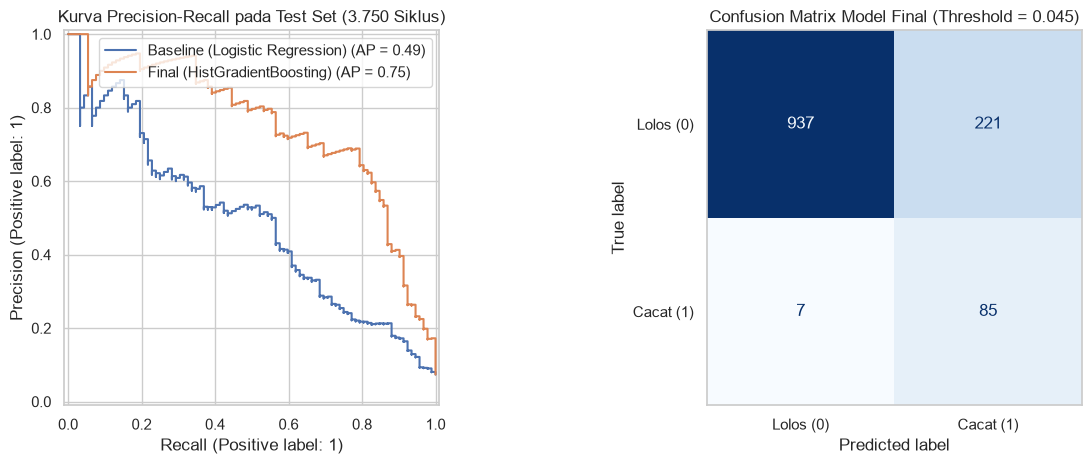

In [6]:
df = pd.read_csv("data/clean.csv")
X = df.drop(columns=["cacat"])
y = df["cacat"].values

_, X_temp, _, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
_, X_test, _, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

base_model = joblib.load("artifacts/baseline_model.joblib")
final_model = joblib.load("artifacts/model.joblib")
tau_final = float(
    meta.get("threshold_bisnis")
    or meta.get("threshold")
    or meta.get("selected_threshold")
    or meta["validation_results"][final_name]["threshold"]
)

y_prob_final = final_model.predict_proba(X_test)[:, 1]
y_pred_final = (y_prob_final >= tau_final).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

PrecisionRecallDisplay.from_estimator(
    base_model, X_test, y_test, name="Baseline (Logistic Regression)", ax=axes[0]
)
PrecisionRecallDisplay.from_estimator(
    final_model, X_test, y_test, name=f"Final ({final_name})", ax=axes[0]
)
axes[0].set_title("Kurva Precision-Recall pada Test Set (3.750 Siklus)")
axes[0].legend(loc="upper right")

cm = confusion_matrix(y_test, y_pred_final)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Lolos (0)", "Cacat (1)"])
disp.plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].grid(False)
axes[1].set_title(f"Confusion Matrix Model Final (Threshold = {tau_final:.3f})")

plt.tight_layout()
fig.savefig("reports/figures/evaluasi_test_set.png", dpi=200, bbox_inches="tight")
plt.show()

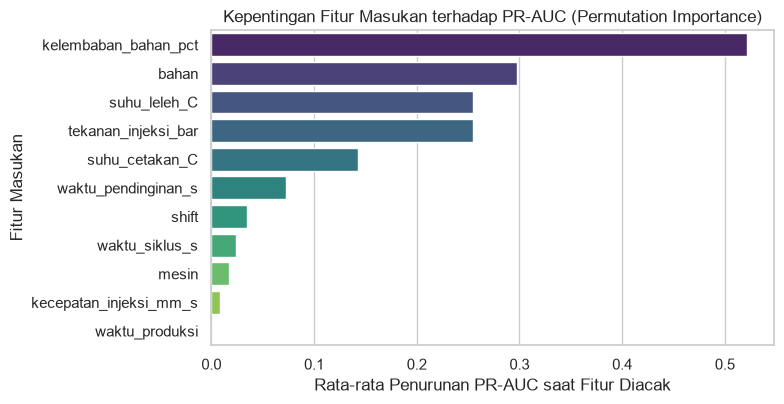

,Fitur Masukan,Penurunan PR-AUC,Std
10,kelembaban_bahan_pct,0.521730,0.025164
3,bahan,0.297500,0.013499
4,suhu_leleh_C,0.254963,0.025205
6,tekanan_injeksi_bar,0.254285,0.011191
5,suhu_cetakan_C,0.142819,0.011992
8,waktu_pendinginan_s,0.073028,0.012513
2,shift,0.034285,0.006172
9,waktu_siklus_s,0.023603,0.001636
1,mesin,0.017005,0.009985
7,kecepatan_injeksi_mm_s,0.008281,0.003275


In [8]:
perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=1,
)
imp_df = pd.DataFrame({
    "Fitur Masukan": X_test.columns,
    "Penurunan PR-AUC": perm.importances_mean,
    "Std": perm.importances_std,
}).sort_values("Penurunan PR-AUC", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(
    data=imp_df,
    x="Penurunan PR-AUC",
    y="Fitur Masukan",
    hue="Fitur Masukan",
    legend=False,
    palette="viridis",
    ax=ax,
)
ax.set_title("Kepentingan Fitur Masukan terhadap PR-AUC (Permutation Importance)")
ax.set_xlabel("Rata-rata Penurunan PR-AUC saat Fitur Diacak")
plt.tight_layout()
fig.savefig("reports/figures/feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

imp_df